In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Values + Variables
span = 38 #ft
step = 0.25 #ft
root_chor see d = 3 #ft
midspan_pt = 6 #ft
tip_chord = 1 #ft
W_max = 1400 #lbs
n = 3 # load factor
E_6061_Aluminum = 10000 # KSI
E_adjusted = E_6061_Aluminum * 1000 * 144
Sigma_max_6061_Aluminum = 35 * 1000 * 144

# Defined Parameters
wingload = (W_max / span) * n
halfspan = (span/2)


# Defining step coords
x = np.arange(0, halfspan, step)
chord = np.zeros_like(x)
for i, xi in enumerate(x):
    if xi <= midspan_pt:
        chord[i] = root_chord
    elif xi <= halfspan:
        chord[i] = -((root_chord - tip_chord)/(halfspan-midspan_pt))*xi + root_chord + ((root_chord - tip_chord)/(halfspan-midspan_pt))*midspan_pt
    else:
        chord[i] = 0
print(x)
print(chord)

# Defining Linear, Elliptical, and Schrenk Load Distributions
chord_load = (chord / np.average(chord))* wingload
elliptical = np.sqrt(1 - (x/(span/2))**2) * (4/np.pi * wingload)
schrenk = (chord_load + elliptical)/2
#print(chord_load)
#print(elliptical)
#print(schrenk * step)

# Adjusting Schrenk to Set of uniform distributed loads on each step
schrenk_step = (schrenk[:-1] + schrenk[1:]) / 2
# x locations for step plot (segment centers)
x_step = (x[:-1] + x[1:]) / 2

# Adjusting test of set of point loads at each step point
Schrenk_step_2 = schrenk * step

#shear = (np.cumsum(np.flip(Schrenk_step_2)))
#moment = (np.cumsum(np.flip(shear * step)))
shear = np.zeros(len(x))
moment = np.zeros(len(x))

for i in range(len(x)):

    loads_outboard = Schrenk_step_2[i:]

    shear[i] = np.sum(loads_outboard)

    distances = np.arange(len(loads_outboard)) * step

    moment[i] = np.sum(loads_outboard * distances)
print((max(moment)))

W_spar = chord / 6
H_spar = chord * 0.12
H_innercut = (H_spar**3 - ((moment * (H_spar/2) * 12) / (Sigma_max_6061_Aluminum * W_spar)))**(1/3)
I = 1/12 * W_spar * ((H_spar)**3 - H_innercut**3)
I_orig = 1/12 * W_spar * (H_spar)**3

curvature = ((moment) / (E_adjusted * I))
print(f"slope of x: {curvature}")
theta = np.cumsum(curvature * step)
deflection = np.cumsum(theta * step)
defl_classic = (Schrenk_step_2 * (step**3))/(3 * E_adjusted * I)

#check
print(f"Inertia: {I}")
print(f"Inertia: {I_orig}")
print(f"deflection: {max(deflection)}")
print(f"defl_classic: {max(defl_classic)}")
print(f"defl_classic: {defl_classic}")
print(np.cumsum(defl_classic))


fig, axs = plt.subplots(5,1, figsize=(8,12))

axs[0].plot(x, Schrenk_step_2)
axs[0].set_title("Lift Distribution")

axs[1].plot(x, shear)
axs[1].set_title("Shear Force")

axs[2].plot(x, moment)
axs[2].set_title("Bending Moment")

axs[3].plot(x, theta)
axs[3].set_title("Wing Theta")

axs[4].plot(x, deflection)
axs[4].set_title("Wing Deflection")

for ax in axs:
    ax.grid(True)

plt.tight_layout()
plt.show()

#print(f"spar width: \n{W_spar*12}")
#print(f"spar height: \n{H_spar*12}")
print(f"spar cap thickness: \n{((H_spar - H_innercut)/2)*12}")
step_theta = -(schrenk_step * step**3) / (6 * E_adjusted * I[:-1])

step_theta = step_theta * (180/np.pi)

#step_y_defl = -((schrenk_step * (x**2))/(24*E_adjusted*I))*((6*halfspan**2) - (4*halfspan*x)+(x**2))


#print(step_theta)

def sum_of_previous_np(arr):
    arr = np.array(arr, dtype=float)  # ensure numeric array
    return np.cumsum(arr)  # subtract current element to exclude it


step_theta_sum = sum_of_previous_np(step_theta)
#print(step_theta_sum)

# step_y_defl_sum = sum_of_previous_np(step_y_defl)*12
# print(step_y_defl_sum)

plt.plot(x, chord_load, label="Chord Distribution")
plt.plot(x, elliptical, label="Elliptical Lift Distribution")
plt.plot(x, schrenk, label="Schrenk Lift Distribution")

plt.step(x_step, schrenk_step, where="mid", label="Segmented Schrenk Load")

plt.xlabel("Spanwise Location (ft)")
plt.ylabel("Value")
plt.title("Wing Distribution")
plt.grid(True)
plt.legend()

plt.show()


plt.plot(x, ((H_spar - H_innercut)/2)*12, label="Spar cap thickness (in)")

plt.xlabel("Spanwise Location (in)")
plt.ylabel("Value")
plt.title("Wing Distribution")
plt.grid(True)
plt.legend()

plt.show()

# beam deflection

#plt.plot(x_step, step_theta_sum, label="deflection slope")
# plt.plot(x_step, step_y_defl_sum, label="wing deflection")



# future steps:
# 1: clean up code, make more easy to follow
# 2: clean up and sanity check shear force and bending moment graphs, make sure layout is correct on all
# 2:
# 3:


# -(w*L^3)/6*E*I
# L = step
# w = schrenk_step
# E = elastic modulus (find value)
# I = 1/12 * W_spar * H_spar^3
  # W_spar = chord / 6
  # H_spar = chord * 0.12
# start at root, add the theta from the previous step

# adjust load to only the vertical component of the lift, recalculate
# continue until convergence

SyntaxError: invalid syntax (59162568.py, line 7)

Front spar height @ 0.25c: 0.4464
Rear  spar height @ 0.6c: 0.3424
Array saved to output.csv successfully.


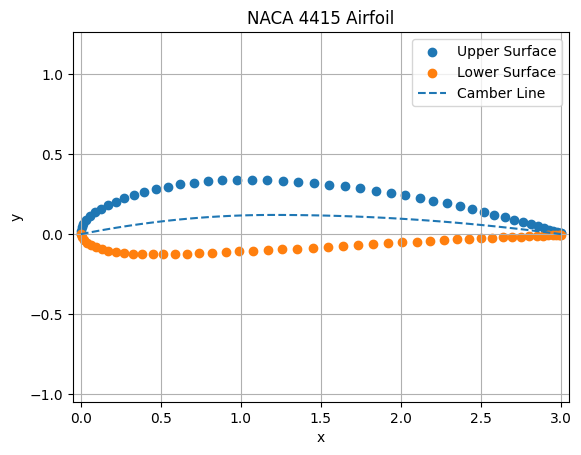

In [ ]:
# Source - https://stackoverflow.com/a/31815812
# Posted by CT Zhu, modified by community. See post 'Timeline' for change history
# Retrieved 2026-04-09, License - CC BY-SA 4.0

%matplotlib inline
import math
import matplotlib.pyplot as plt
import numpy as np

#https://en.wikipedia.org/wiki/NACA_airfoil#Equation_for_a_cambered_4-digit_NACA_airfoil
def camber_line( x, m, p, c ):
    return np.where((x>=0)&(x<=(c*p)),
                    m * (x / np.power(p,2)) * (2.0 * p - (x / c)),
                    m * ((c - x) / np.power(1-p,2)) * (1 + (x / c) - 2.0 * p ))

def dyc_over_dx( x, m, p, c ):
    return np.where((x>=0)&(x<=(c*p)),
                    ((2.0 * m) / np.power(p,2)) * (p - x / c),
                    ((2.0 * m ) / np.power(1-p,2)) * (p - x / c ))

def thickness( x, t, c ):
    xc = x / c
    return 5 * t * c * (
        0.2969*np.sqrt(xc)
        - 0.1260*xc
        - 0.3516*xc**2
        + 0.2843*xc**3
        - 0.1015*xc**4
    )

def naca4(x, m, p, t, c=1):
    dyc_dx = dyc_over_dx(x, m, p, c)
    th = np.arctan(dyc_dx)
    yt = thickness(x, t, c)
    yc = camber_line(x, m, p, c)

    xu = x - yt*np.sin(th)
    yu = yc + yt*np.cos(th)

    xl = x + yt*np.sin(th)
    yl = yc - yt*np.cos(th)

    return (xu, yu), (xl, yl)


# ---- PARAMETERS (NACA 2412) ----
m = 0.04
p = 0.4
t = 0.15
c = 3

# IMPORTANT: scale x to chord

def cosspace_np(start, stop, num, endpoint=True):
    theta = np.linspace(0, np.pi, num, endpoint=endpoint)
    return start + (stop - start) * (1 - np.cos(theta)) / 2

x = np.linspace(0, c, 100)
xcos = cosspace_np(0,c,50)
# ---- COMPUTE AIRFOIL ----
( xu, yu ), ( xl, yl ) = naca4(xcos, m, p, t, c)
data = ( xu, yu )

def spar_height(xu, yu, xl, yl, x_spar):
    # interpolate upper and lower surface at spar x-location
    y_upper = np.interp(x_spar, xu, yu)
    y_lower = np.interp(x_spar, xl, yl)

    height = y_upper - y_lower
    return height, y_upper, y_lower


# Spar positions (fraction of chord)
n_front = 0.25
n_rear  = 0.60

x_front = n_front * c
x_rear  = n_rear * c

# Compute spar heights
h_front, yuf, ylf = spar_height(xu, yu, xl, yl, x_front)
h_rear,  yur, ylr = spar_height(xu, yu, xl, yl, x_rear)

print(f"Front spar height @ {n_front}c: {h_front:.4f}")
print(f"Rear  spar height @ {n_rear}c: {h_rear:.4f}")


try:
    # Save array to CSV
    np.savetxt(f"NACA {int(m*100)}{int(p*10)}{int(t*100)} Airfoil.csv", data, delimiter=",", fmt="%d", header="Col1,Col2,Col3", comments="")
    print("Array saved to output.csv successfully.")
except Exception as e:
    print(f"Error saving CSV: {e}")




# ---- PLOT ----
plt.figure()

plt.scatter(xu, yu, label="Upper Surface")
plt.scatter(xl, yl, label="Lower Surface")
plt.plot(x, camber_line(x, m, p, c), '--', label="Camber Line")
plt.title(f"NACA {int(m*100)}{int(p*10)}{int(t*100)} Airfoil")
plt.xlabel("x")
plt.ylabel("y")

plt.axis('equal')
plt.grid()
plt.legend()

plt.xlim(-0.05, c + 0.05)

plt.show()

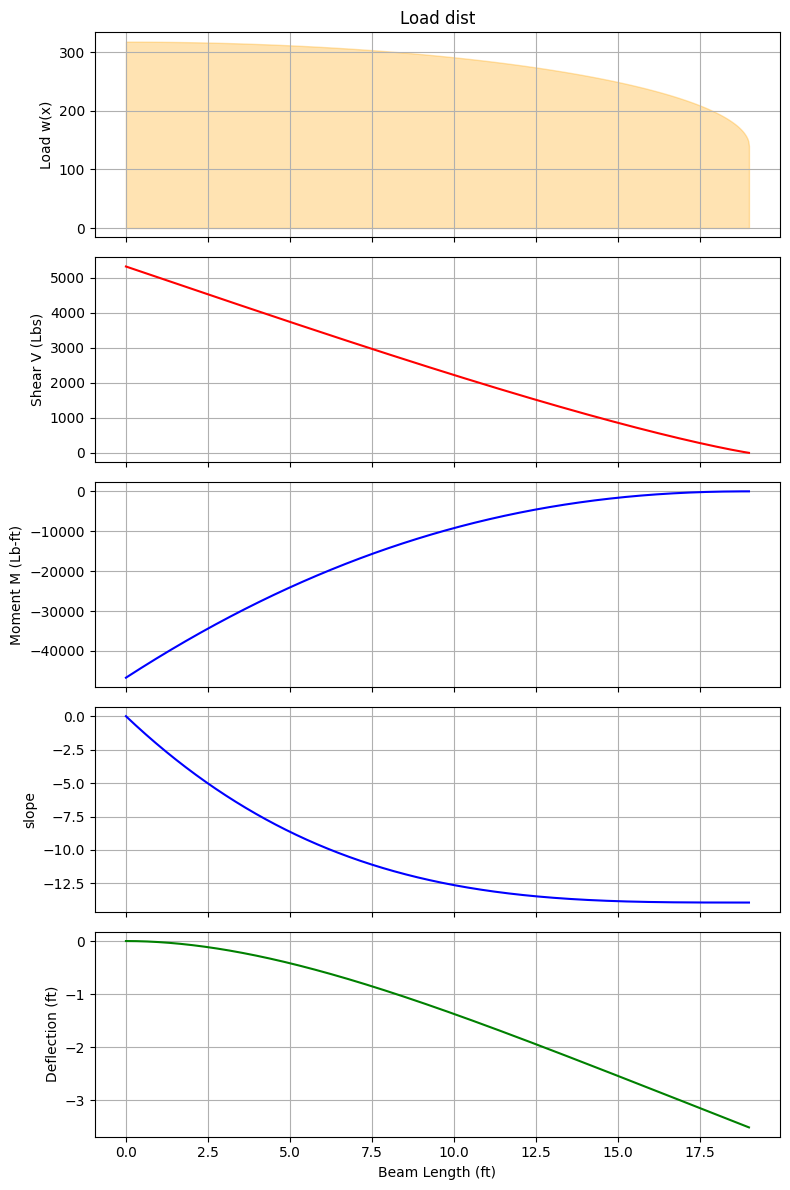

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#chord_load = (chord / np.average(chord))* wingload
#elliptical = np.sqrt(1 - (x/(span/2))**2) * (4/np.pi * wingload)
#schrenk = (chord_load + elliptical)/2

E_6061_Aluminum = 10000 # KSI
E_adjusted = E_6061_Aluminum * 1000 * 144

L=19
w0= 1400
E= E_adjusted
I = 8e-4
n=1000
k_iter = 5
x = np.linspace(0, L, n)
dx = x[1] - x[0]
N = 3.8

wingload = (w0 / L) * N
w_ellipse = wingload * np.sqrt(1-(x/L)**2) * (4/np.pi)
w_linear = wingload
w = (w_ellipse + w_linear) / 2

V = np.zeros_like(x)
for i in range(n-2,-1,-1):
    V[i] = V[i+1] + (w[i] + w[i+1]) * 0.5 * dx

M = np.zeros_like(x)
for i in range(n-2,-1,-1):
    M[i] = M[i+1] - (V[i] + V[i+1]) * 0.5 * dx

M_EI = M / (E*I)
theta = np.zeros_like(x)
for i in range(1,n):
    theta[i] = theta[i-1] + (M_EI[i-1] + M_EI[i]) * 0.5 * dx

delta = np.zeros_like(x)
for i in range(1,n):
    delta[i] = delta[i-1] + (theta[i-1] + theta[i]) * 0.5 * dx

fig, axs = plt.subplots(5, 1, figsize=(8,12), sharex=True)

axs[0].fill_between(x, 0, w, color='orange', alpha=0.3)
axs[0].set_ylabel('Load w(x)')
axs[0].set_title("Load dist")

axs[1].plot(x, V, 'r')
axs[1].set_ylabel('Shear V (Lbs)')

axs[2].plot(x, M, 'b')
axs[2].set_ylabel('Moment M (Lb-ft)')

axs[3].plot(x, theta * (180/np.pi), 'b')
axs[3].set_ylabel('slope')

axs[4].plot(x, delta, 'g')
axs[4].set_ylabel('Deflection (ft)')
axs[4].set_xlabel('Beam Length (ft)')

for ax in axs: ax.grid(True)
plt.tight_layout()
plt.show()

Front spar height @ 0.25c: 0.4467
Rear  spar height @ 0.6c: 0.3426
Converged in 1 iterations


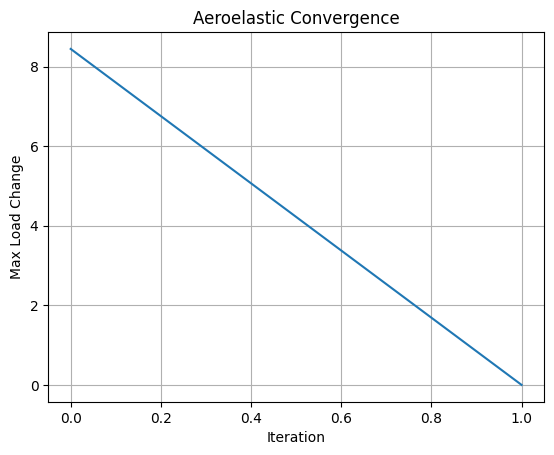

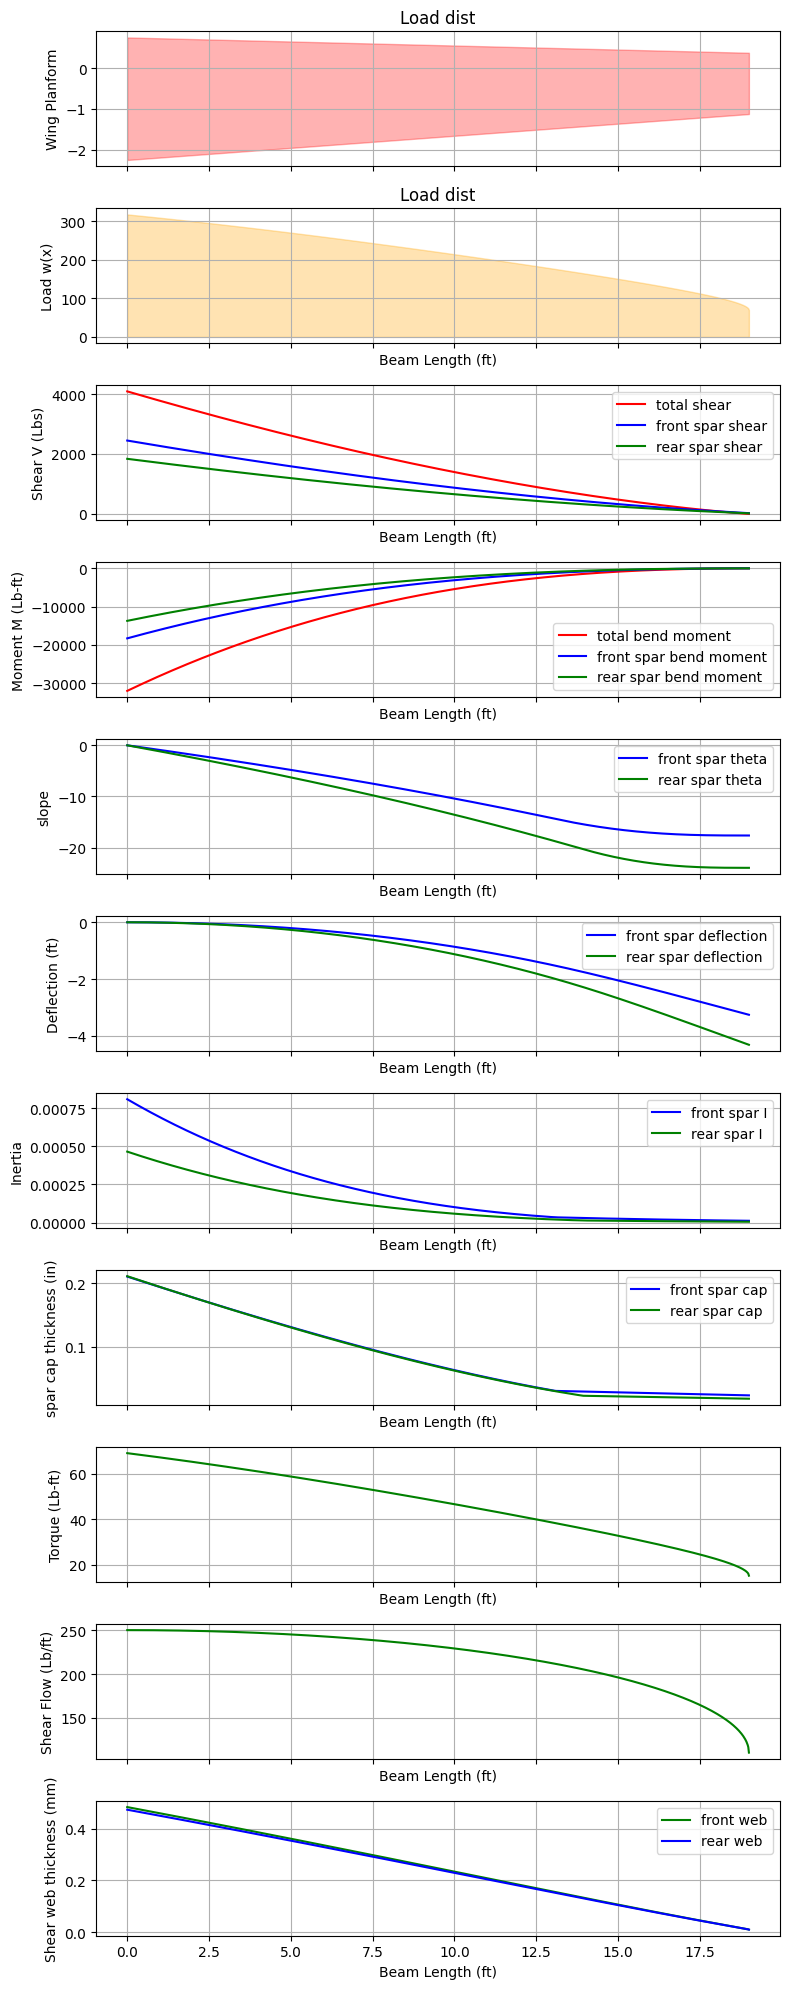

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


L = 19
w0 = 1400
n = 1000
k_iter = 5
x = np.linspace(0, L, n)
dx = x[1] - x[0]
N = 3.8
E_6061_Aluminum = 10000  # KSI
E_adjusted = E_6061_Aluminum * 1000 * 144
E = E_adjusted
Sigma_max_6061_Aluminum = 35 * 1000 * 144
Sigma_max_shear_6061_Aluminum = 24 * 1000 * 144
chord_root = 3
taper = 0.5
chord_tip = chord_root * taper
chord_L = chord_root - ((chord_root - chord_tip) / L) * x
chord_lead = chord_L / 4
chord_trail = -chord_L * (3 / 4)
chord_cp = 0.4
front_spar = 0.25
rear_spar = 0.6

wingload = ((w0 / L) * N) * (chord_L / chord_root)
w_ellipse = wingload * np.sqrt(1 - (x / L) ** 2) * (4 / np.pi)
w_linear = wingload
w_0 = (w_ellipse + w_linear) / 2


def naca4(xc, m, p, t, c=1):
    """Return ((xu, yu), (xl, yl)) for a NACA 4-digit airfoil.
    xc: chordwise stations in the same units as c (0..c)."""
    def camber_line(x, m, p, c):
        return np.where((x >= 0) & (x <= (c * p)),
                        m * (x / np.power(p, 2)) * (2.0 * p - (x / c)),
                        m * ((c - x) / np.power(1 - p, 2)) * (1 + (x / c) - 2.0 * p))

    def dyc_over_dx(x, m, p, c):
        return np.where((x >= 0) & (x <= (c * p)),
                        ((2.0 * m) / np.power(p, 2)) * (p - x / c),
                        ((2.0 * m) / np.power(1 - p, 2)) * (p - x / c))

    def thickness(x, t, c):
        xc_ = x / c
        return 5 * t * c * (
            0.2969 * np.sqrt(np.clip(xc_, 0, None))
            - 0.1260 * xc_
            - 0.3516 * xc_ ** 2
            + 0.2843 * xc_ ** 3
            - 0.1015 * xc_ ** 4
        )

    dyc_dx = dyc_over_dx(xc, m, p, c)
    th = np.arctan(dyc_dx)
    yt = thickness(xc, t, c)
    yc = camber_line(xc, m, p, c)

    xu = xc - yt * np.sin(th)
    yu = yc + yt * np.cos(th)

    xl = xc + yt * np.sin(th)
    yl = yc - yt * np.cos(th)

    return (xu, yu), (xl, yl)


# ---- PARAMETERS (NACA 2412) ----
m = 0.04
p = 0.4
t = 0.15
c = chord_root  # airfoil chord at the root (3 ft)

# Airfoil is defined over its own chord (0..c), not the span (0..L)
x_chord = np.linspace(0, c, n)
(xu, yu), (xl, yl) = naca4(x_chord, m, p, t, c)


def spar_height(xu, yu, xl, yl, x_spar):
    # interpolate upper and lower surface at spar x-location
    y_upper = np.interp(x_spar, xu, yu)
    y_lower = np.interp(x_spar, xl, yl)

    height = y_upper - y_lower
    return height, y_upper, y_lower


# Spar positions (chordwise, in the same units as the airfoil)
x_front = front_spar * c
x_rear = rear_spar * c

# Spar heights at the root chord
h_front, yuf, ylf = spar_height(xu, yu, xl, yl, x_front)
h_rear, yur, ylr = spar_height(xu, yu, xl, yl, x_rear)

print(f"Front spar height @ {front_spar}c: {h_front:.4f}")
print(f"Rear  spar height @ {rear_spar}c: {h_rear:.4f}")

# Scale spar heights to the local chord along the span
chord_scale = chord_L / c


def solve_beam_all(w_input, W_spar_f, H_spar_f, W_spar_r, H_spar_r, E, Sigma_allow, Sigma_allow_2,
                   x, dx, max_iter=100, tol=1e-5):

    n = len(x)

    w_curr = w_input.copy()

    deflection_history = []
    error_history = []

    for k in range(max_iter):
        V, M = np.zeros_like(x), np.zeros_like(x)

        for i in range(n - 2, -1, -1):
            V[i] = V[i + 1] + (w_input[i] + w_input[i + 1]) * 0.5 * dx
            M[i] = M[i + 1] - (V[i] + V[i + 1]) * 0.5 * dx

        c_f = H_spar_f / 2
        c_r = H_spar_r / 2

        # spar distribution
        front_ratio = (rear_spar - chord_cp) / (rear_spar - front_spar)
        L_f = w_0 * front_ratio
        L_r = w_0 - L_f
        V_f = V * front_ratio
        V_r = V - V_f
        M_f = M * front_ratio
        M_r = M - M_f

        # required inertia on front spar from bending stress constraint
        I_req_m_f = np.abs(M_f) * c_f / Sigma_max_6061_Aluminum

        # full section inertia
        I_full_m_f = (1 / 12) * W_spar_f * H_spar_f ** 3

        # enforce minimum structure
        I_req_m_f = np.maximum(I_req_m_f, 0.05 * I_full_m_f)

        # solve for inner cutout
        H_innercut_m_f = (H_spar_f ** 3 - (12 * I_req_m_f / W_spar_f)) ** (1 / 3)

        # prevent invalid geometry
        H_innercut_m_f = np.clip(H_innercut_m_f, 0, H_spar_f * 0.99)

        # final inertia
        I_m_f = (1 / 12) * W_spar_f * (H_spar_f ** 3 - H_innercut_m_f ** 3)

        cap_thickness_f = (H_spar_f - H_innercut_m_f) / 2

        # required inertia on rear spar from bending stress constraint
        I_req_m_r = np.abs(M_r) * c_r / Sigma_max_6061_Aluminum

        # full section inertia
        I_full_m_r = (1 / 12) * W_spar_r * H_spar_r ** 3

        # enforce minimum structure
        I_req_m_r = np.maximum(I_req_m_r, 0.05 * I_full_m_r)

        # solve for inner cutout
        H_innercut_m_r = (H_spar_r ** 3 - (12 * I_req_m_r / W_spar_r)) ** (1 / 3)

        # prevent invalid geometry
        H_innercut_m_r = np.clip(H_innercut_m_r, 0, H_spar_r * 0.99)

        # final inertia
        I_m_r = (1 / 12) * W_spar_r * (H_spar_r ** 3 - H_innercut_m_r ** 3)

        cap_thickness_r = (H_spar_r - H_innercut_m_r) / 2

        # Torque
        A_t = 0.5 * (H_spar_f + H_spar_r) * (rear_spar - front_spar)
        cg_t = ((H_spar_r + 2 * H_spar_f) / (3 * (H_spar_f + H_spar_r))) * (rear_spar - front_spar)
        d_t = np.abs(chord_cp - cg_t)
        T = w_input * d_t

        # Shear Flow
        q = T / (2 * A_t)
        V_sf = q * H_spar_f
        V_sr = q * H_spar_r
        V_f = V_f + V_sf
        V_r = V_r + V_sr
        b_thf = V_f / (Sigma_max_shear_6061_Aluminum * H_spar_f)
        b_thr = V_r / (Sigma_max_shear_6061_Aluminum * H_spar_r)

        theta_f, delta_f = np.zeros_like(x), np.zeros_like(x)
        theta_r, delta_r = np.zeros_like(x), np.zeros_like(x)
        M_EI_f = M_f / (E * I_m_f)
        M_EI_r = M_r / (E * I_m_r)

        for i in range(1, n):
            theta_f[i] = theta_f[i - 1] + (M_EI_f[i - 1] + M_EI_f[i]) * 0.5 * dx
            delta_f[i] = delta_f[i - 1] + (theta_f[i - 1] + theta_f[i]) * 0.5 * dx
            theta_r[i] = theta_r[i - 1] + (M_EI_r[i - 1] + M_EI_r[i]) * 0.5 * dx
            delta_r[i] = delta_r[i - 1] + (theta_r[i - 1] + theta_r[i]) * 0.5 * dx

        # store history
        deflection_history.append(delta_f.copy())
        deflection_history.append(delta_r.copy())

        # -----------------------------
        # Aeroelastic update
        # -----------------------------
        w_next = w_input * np.cos((theta_f + theta_r) / 2)

        error = np.max(np.abs(w_next - w_curr))
        error_history.append(error)

        if error < tol:
            print(f"Converged in {k} iterations")
            break

        w_curr = w_next.copy()

    return (V, V_f, V_r, V_sf, V_sr, M, M_f, M_r, theta_f, delta_f, theta_r, delta_r,
            I_m_f, I_m_r, cap_thickness_f, cap_thickness_r, b_thf, b_thr, T, q,
            deflection_history, error_history)


(V, V_f, V_r, V_sf, V_sr, M, M_f, M_r, theta_f, delta_f, theta_r, delta_r,
 I_m_f, I_m_r, cap_thickness_f, cap_thickness_r, b_thf, b_thr, T, q,
 deflection_history, error_history) = solve_beam_all(
    w_input=w_0,
    W_spar_f=chord_L / 6,
    H_spar_f=h_front * chord_scale,
    W_spar_r=chord_L / 6,
    H_spar_r=h_rear * chord_scale,
    E=E_adjusted,
    Sigma_allow=Sigma_max_6061_Aluminum,
    Sigma_allow_2=Sigma_max_shear_6061_Aluminum,
    x=x,
    dx=dx
)

plt.figure()
plt.plot(error_history)
plt.xlabel("Iteration")
plt.ylabel("Max Load Change")
plt.title("Aeroelastic Convergence")
plt.grid()
plt.show()

fig, axs = plt.subplots(11, 1, figsize=(8, 20), sharex=True)

axs[0].fill_between(x, chord_lead, chord_trail, where=(chord_lead > chord_trail), color='red', alpha=0.3)
axs[0].set_ylabel('Wing Planform')
axs[0].set_title("Load dist")

axs[1].fill_between(x, 0, w_0, color='orange', alpha=0.3)
axs[1].set_ylabel('Load w(x)')
axs[1].set_title("Load dist")
axs[1].set_xlabel('Beam Length (ft)')

axs[2].plot(x, V, label="total shear", color='r')
axs[2].plot(x, V_f, label="front spar shear", color='b')
axs[2].plot(x, V_r, label="rear spar shear", color='g')
axs[2].set_ylabel('Shear V (Lbs)')
axs[2].set_xlabel('Beam Length (ft)')
axs[2].legend()

axs[3].plot(x, M, label="total bend moment", color='r')
axs[3].plot(x, M_f, label="front spar bend moment", color='b')
axs[3].plot(x, M_r, label="rear spar bend moment", color='g')
axs[3].set_ylabel('Moment M (Lb-ft)')
axs[3].set_xlabel('Beam Length (ft)')
axs[3].legend()

axs[4].plot(x, theta_f * (180 / np.pi), label="front spar theta", color='b')
axs[4].plot(x, theta_r * (180 / np.pi), label="rear spar theta", color='g')
axs[4].set_ylabel('slope')
axs[4].set_xlabel('Beam Length (ft)')
axs[4].legend()

axs[5].plot(x, delta_f, label="front spar deflection", color='b')
axs[5].plot(x, delta_r, label="rear spar deflection", color='g')
axs[5].set_ylabel('Deflection (ft)')
axs[5].set_xlabel('Beam Length (ft)')
axs[5].legend()

axs[6].plot(x, I_m_f, 'b', label="front spar I")
axs[6].plot(x, I_m_r, 'g', label="rear spar I")
axs[6].set_ylabel('Inertia')
axs[6].set_xlabel('Beam Length (ft)')
axs[6].legend()

axs[7].plot(x, cap_thickness_f * 12, label="front spar cap", color='b')
axs[7].plot(x, cap_thickness_r * 12, label="rear spar cap", color='g')
axs[7].set_ylabel('spar cap thickness (in)')
axs[7].set_xlabel('Beam Length (ft)')
axs[7].legend()

axs[8].plot(x, T, 'g')
axs[8].set_ylabel('Torque (Lb-ft)')
axs[8].set_xlabel('Beam Length (ft)')

axs[9].plot(x, q, 'g')
axs[9].set_ylabel('Shear Flow (Lb/ft)')
axs[9].set_xlabel('Beam Length (ft)')

axs[10].plot(x, b_thf * 12 * 25.4, 'g', label="front web")
axs[10].plot(x, b_thr * 12 * 25.4, 'b', label="rear web")
axs[10].set_ylabel('Shear web thickness (mm)')
axs[10].set_xlabel('Beam Length (ft)')
axs[10].legend()

for ax in axs:
    ax.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


L=19
w0= 1400
# I = 5e-4
n=1000
k_iter = 5
x = np.linspace(0, L, n)
dx = x[1] - x[0]
N = 3.8
E_6061_Aluminum = 10000 # KSI
E_adjusted = E_6061_Aluminum * 1000 * 144
E = E_adjusted
Sigma_max_6061_Aluminum = 35 * 1000 * 144
Sigma_max_shear_6061_Aluminum = 24 * 1000 * 144
chord_root = 3
taper = 0.5
chord_tip = chord_root * taper
chord_L = chord_root - ((chord_root -chord_tip ) / L) * x
chord_lead = chord_L / 4
chord_trail = -chord_L * (3/4)
chord_cp = 0.4
front_spar = 0.25
rear_spar = 0.6

wingload = ((w0 / L) * N)*(chord_L / chord_root)
w_ellipse = wingload * np.sqrt(1-(x/L)**2) * (4/np.pi)
w_linear = wingload
w_0 = (w_ellipse + w_linear) / 2

def naca4(x, m, p, t, c=1):
  def camber_line( x, m, p, c ):
    return np.where((x>=0)&(x<=(c*p)),
                    m * (x / np.power(p,2)) * (2.0 * p - (x / c)),
                    m * ((c - x) / np.power(1-p,2)) * (1 + (x / c) - 2.0 * p ))
  def dyc_over_dx( x, m, p, c ):
    return np.where((x>=0)&(x<=(c*p)),
                    ((2.0 * m) / np.power(p,2)) * (p - x / c),
                    ((2.0 * m ) / np.power(1-p,2)) * (p - x / c ))
  def thickness( x, t, c ):
    xc = x / c
    return 5 * t * c * (
        0.2969*np.sqrt(xc)
        - 0.1260*xc
        - 0.3516*xc**2
        + 0.2843*xc**3
        - 0.1015*xc**4
    )

  dyc_dx = dyc_over_dx(x, m, p, c)
  th = np.arctan(dyc_dx)
  yt = thickness(x, t, c)
  yc = camber_line(x, m, p, c)

  xu = x - yt*np.sin(th)
  yu = yc + yt*np.cos(th)

  xl = x + yt*np.sin(th)
  yl = yc - yt*np.cos(th)

  return (xu, yu), (xl, yl)

# ---- PARAMETERS (NACA 2412) ----
#x1 = np.linspace(0, chord_L, n)
m = 0.04
p = 0.4
t = 0.15
c = 3

(xu, yu, xl, yl) = naca4(x, m, p, t, c)


def spar_height(xu, yu, xl, yl, x_spar):
    # interpolate upper and lower surface at spar x-location
    y_upper = np.interp(x_spar, xu, yu)
    y_lower = np.interp(x_spar, xl, yl)

    height = y_upper - y_lower
    return height, y_upper, y_lower


# Spar positions (fraction of chord)
x_front = front_spar * c
x_rear  = rear_spar * c

# Compute spar heights
h_front, yuf, ylf = spar_height(xu, yu, xl, yl, x_front)
h_rear,  yur, ylr = spar_height(xu, yu, xl, yl, x_rear)

print(f"Front spar height @ {n_front}c: {h_front:.4f}")
print(f"Rear  spar height @ {n_rear}c: {h_rear:.4f}")




# cp: stall: a=-14.6, x=1.608/5 (0.3216), climb: a=3.4, x=2.196/5 (0.4392), cruise: a=0, x=3.056/5 (0.6112), vne: a=-0.8, x=3.525/5 (0.705).

# future implementations:
# add deflection from torsion, twisting
# refine buckling loads, fix math issues with low plate bucking thickness, define where stiffeners are needed and the spacings between ribs
# add naca foil code, define spar height and spar cap geometry relative to upper and lower skin of foil
# calculate mass and cg of each wing section, subtract from lift dist and rerun
# define ideal rivet placement
# general UI fixes
def solve_beam_all(w_input, W_spar_f, H_spar_f, W_spar_r, H_spar_r, E, Sigma_allow, Sigma_allow_2, x, dx, max_iter=100, tol=1e-5):

  n = len(x)

  w_curr = w_input.copy()

  deflection_history = []
  error_history = []

  for k in range(max_iter):
    V, M = np.zeros_like(x), np.zeros_like(x)

    for i in range(n-2, -1, -1):
        V[i] = V[i+1] + (w_input[i] + w_input[i+1]) * 0.5 * dx
        M[i] = M[i+1] - (V[i] + V[i+1]) * 0.5 * dx

    c_f = H_spar_f / 2
    c_r = H_spar_r / 2

    # spar distribution
    front_ratio = (rear_spar - chord_cp) / (rear_spar - front_spar)
    L_f = w_0*(front_ratio)
    L_r = (w_0 - L_f)
    V_f = V*front_ratio
    V_r = V-V_f
    M_f = M*front_ratio
    M_r = M-M_f

    # required inertia on front spar from bending stress constraint
    I_req_m_f = np.abs(M_f) * c_f / Sigma_max_6061_Aluminum

    # full section inertia
    I_full_m_f= (1/12) * W_spar_f * H_spar_f**3

    # enforce minimum structure
    I_req_m_f = np.maximum(I_req_m_f, 0.05 * I_full_m_f)

    # solve for inner cutout
    H_innercut_m_f = (H_spar_f**3 - (12 * I_req_m_f / W_spar_f))**(1/3)

    # prevent invalid geometry
    H_innercut_m_f = np.clip(H_innercut_m_f, 0, H_spar_f * 0.99)

    # final inertia
    I_m_f = (1/12) * W_spar_f * (H_spar_f**3 - H_innercut_m_f**3)

    cap_thickness_f = (H_spar_f - H_innercut_m_f)/2


    # required inertia on rear spar from bending stress constraint
    I_req_m_r = np.abs(M_r) * c_r / Sigma_max_6061_Aluminum

    # full section inertia
    I_full_m_r = (1/12) * W_spar_r * H_spar_r**3

    # enforce minimum structure
    I_req_m_r = np.maximum(I_req_m_r, 0.05 * I_full_m_r)

    # solve for inner cutout
    H_innercut_m_r = (H_spar_r**3 - (12 * I_req_m_r / W_spar_r))**(1/3)

    # prevent invalid geometry
    H_innercut_m_r = np.clip(H_innercut_m_r, 0, H_spar_r * 0.99)

    # final inertia
    I_m_r = (1/12) * W_spar_r * (H_spar_r**3 - H_innercut_m_r**3)

    cap_thickness_r = (H_spar_r - H_innercut_m_r) / 2


    #V*Q / I*b Q = A * y = (h/2) * b * h/4
    # V*Q = Sigma_max_shear_6061_Aluminum * I*b
    #b_thf = (V_f * ((H_spar_f - H_innercut_m_f)/2) * W_spar_f * (H_spar_f/4))/(Sigma_max_shear_6061_Aluminum * I_m_f)

    # Torque
    A_t = 0.5*(H_spar_f + H_spar_r)* (rear_spar - front_spar)
    cg_t = ((H_spar_r + 2*H_spar_f)/(3*(H_spar_f + H_spar_r)))*(rear_spar - front_spar)
    d_t = np.abs(chord_cp - cg_t)
    T = w_input * d_t

    # Shear Flow
    q = T/(2*A_t)
    V_sf = q*H_spar_f
    V_sr = q*H_spar_r
    V_f = V_f + V_sf
    V_r = V_r + V_sr
    b_thf = V_f / (Sigma_max_shear_6061_Aluminum * H_spar_f)
    b_thr = V_r / (Sigma_max_shear_6061_Aluminum * H_spar_r)

    n_f = 4
    k = (1/n_f)**0.5


    tol = 1e-6
    max_iter = 100

#    for i in range(max_iter):
        # Eqn (1): induced stress
#        F_induced_f = q / b_thf
#        F_induced_r = q / b_thr

        # Eqn (2): updated thickness from buckling
#        t_new_f = b_thf * np.sqrt(F_induced_f / (k * E))
#        t_new_r = b_thr * np.sqrt(F_induced_r / (k * E))

        # check convergence
#        if (np.all(np.abs(t_new_f - b_thf) < tol) and
#            np.all(np.abs(t_new_r - b_thr) < tol) and
#            np.all(np.abs(t_new_f  > (V_f / (Sigma_max_shear_6061_Aluminum * H_spar_f)))) and
#            np.all(np.abs(t_new_r  > (V_r / (Sigma_max_shear_6061_Aluminum * H_spar_r))))):

#            print(f"Both spars converged in {i+1} iterations")
#            break

#        b_thf = t_new_f
#        b_thr = t_new_r

#    print(f"Final Front web thickness (min/max): {(b_thf.min()*12*25.4):.6f} / {(b_thf.max()*12*25.4):.6f} mm")
#    print(f"Final Front induced stress (min/max): {(F_induced_f.min())/1000/144:.4f} / {(F_induced_f.max())/1000/144:.4f} Lb/ft^2")

#    print(f"Final Rear web thickness (min/max): {(b_thr.min()*12*25.4):.6f} / {(b_thr.max()*12*25.4):.6f} mm")
#    print(f"Final Rear induced stress (min/max): {F_induced_r.min():.4f} / {F_induced_r.max():.4f} Lb/ft^2")






    theta_f, delta_f = np.zeros_like(x), np.zeros_like(x)
    theta_r, delta_r = np.zeros_like(x), np.zeros_like(x)
    M_EI_f = M_f / (E * I_m_f)
    M_EI_r = M_r / (E * I_m_r)

    for i in range(1, n):
        theta_f[i] = theta_f[i-1] + (M_EI_f[i-1] + M_EI_f[i]) * 0.5 * dx
        delta_f[i] = delta_f[i-1] + (theta_f[i-1] + theta_f[i]) * 0.5 * dx
        theta_r[i] = theta_r[i-1] + (M_EI_r[i-1] + M_EI_r[i]) * 0.5 * dx
        delta_r[i] = delta_r[i-1] + (theta_r[i-1] + theta_r[i]) * 0.5 * dx

     # store history
    deflection_history.append(delta_f.copy())
    deflection_history.append(delta_r.copy())

        # -----------------------------
        # Aeroelastic update
        # -----------------------------
    w_next = w_input * np.cos((theta_f + theta_r)/2)

    error = np.max(np.abs(w_next - w_curr))
    error_history.append(error)

    if error < tol:
            print(f"Converged in {k} iterations")
            break

    w_curr = w_next.copy()

  return V, V_f, V_r, V_sf, V_sr, M, M_f, M_r, theta_f, delta_f, theta_r, delta_r, I_m_f, I_m_r, cap_thickness_f, cap_thickness_r, b_thf, b_thr, T, q, deflection_history, error_history



V, V_f, V_r, V_sf, V_sr, M, M_f, M_r, theta_f, delta_f, theta_r, delta_r, I_m_f, I_m_r, cap_thickness_f, cap_thickness_r, b_thf, b_thr, T, q, deflection_history, error_history = solve_beam_all(
    w_input=w_0,
    W_spar_f=chord_L/6,
    H_spar_f=chord_L*h_front,
    W_spar_r=chord_L/6,
    H_spar_r=chord_L*h_rear,
    E=E_adjusted,
    Sigma_allow=Sigma_max_6061_Aluminum,
    Sigma_allow_2 = Sigma_max_shear_6061_Aluminum,
    x=x,
    dx=dx

)
plt.figure()
plt.plot(error_history)
plt.xlabel("Iteration")
plt.ylabel("Max Load Change")
plt.title("Aeroelastic Convergence")
plt.grid()
plt.show()

fig, axs = plt.subplots(11, 1, figsize=(8,20), sharex=True)

axs[0].fill_between(x, chord_lead, chord_trail, where=(chord_lead > chord_trail), color='red', alpha=0.3)
axs[0].set_ylabel('Wing Planform')
axs[0].set_title("Load dist")

axs[1].fill_between(x, 0, w_0, color='orange', alpha=0.3)
axs[1].set_ylabel('Load w(x)')
axs[1].set_title("Load dist")
axs[1].set_xlabel('Beam Length (ft)')

axs[2].plot(x, V, label = "total shear", color =   'r')
axs[2].plot(x, V_f, label = "front spar shear", color = 'b')
axs[2].plot(x, V_r, label = "rear spar shear", color = 'g')
axs[2].set_ylabel('Shear V (Lbs)')
axs[2].set_xlabel('Beam Length (ft)')
axs[2].legend()

axs[3].plot(x, M, label = "total bend moment", color =  'r')
axs[3].plot(x, M_f, label = "front spar bend moment", color = 'b')
axs[3].plot(x, M_r, label = "rear spar bend moment", color = 'g')
axs[3].set_ylabel('Moment M (Lb-ft)')
axs[3].set_xlabel('Beam Length (ft)')
axs[3].legend()

axs[4].plot(x, theta_f * (180/np.pi), label = "front spar theta", color = 'b')
axs[4].plot(x, theta_r * (180/np.pi), label = "rear spar theta", color = 'g')
axs[4].set_ylabel('slope')
axs[4].set_xlabel('Beam Length (ft)')
axs[4].legend()

axs[5].plot(x, delta_f, label = "front spar deflection", color = 'b')
axs[5].plot(x, delta_r, label = "rear spar deflection", color = 'g')
axs[5].set_ylabel('Deflection (ft)')
axs[5].set_xlabel('Beam Length (ft)')
axs[5].legend()

axs[6].plot(x, I_m_f, 'g')
axs[6].plot(x, I_m_r, 'g')
axs[6].set_ylabel('Inertia')
axs[6].set_xlabel('Beam Length (ft)')

axs[7].plot(x, cap_thickness_f *12, label = "front spar cap", color = 'b')
axs[7].plot(x, cap_thickness_r *12, label = "rear spar cap", color = 'g')
axs[7].set_ylabel('spar cap thickness (in)')
axs[7].set_xlabel('Beam Length (ft)')
axs[7].legend()

axs[8].plot(x, T, 'g')
axs[8].set_ylabel('Torque (Lb-ft)')
axs[8].set_xlabel('Beam Length (ft)')

axs[9].plot(x, q, 'g')
axs[9].set_ylabel('Shear Flow (Lb/ft)')
axs[9].set_xlabel('Beam Length (ft)')

axs[10].plot(x, b_thf*12*25.4, 'g')
axs[10].plot(x, b_thr*12*25.4, 'b')
axs[10].set_ylabel('Shear web thickness (mm)')
axs[10].set_xlabel('Beam Length (ft)')

for ax in axs: ax.grid(True)
plt.tight_layout()
plt.show()


NameError: name 'xu' is not defined

In [ ]:
import numpy as np

# geometry
b = spanwise distance between spars (mm)
h = spar height (mm)

A = b * h  # enclosed area (single cell)

# panel lengths (rectangle)
s_top = b
s_bottom = b
s_front = h
s_rear = h

# thicknesses (can be arrays or scalars)
t_top = t_top
t_bottom = t_bottom
t_front = t_front
t_rear = t_rear

sum_ds_over_t = (s_top/t_top +
                 s_bottom/t_bottom +
                 s_front/t_front +
                 s_rear/t_rear)

J = (4 * A**2) / sum_ds_over_t

theta_prime = T / (G * J)